# Анализ и прогнозирование временных рядов методами искусственного интеллекта
# Артемьев М.О. ЕТ-228
## **Практическая работа 5. Поиск типичных подпоследовательностей временного ряда.**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os

practice_dir_path = '/content/drive/MyDrive/05 Snippets'
os.chdir(practice_dir_path)

print("Рабочая папка:", os.getcwd())
print("Содержимое:", os.listdir())

Mounted at /content/drive
Рабочая папка: /content/drive/MyDrive/05 Snippets
Содержимое: ['datasets', 'modules', '05 Snippets.ipynb']


In [3]:
%load_ext autoreload
%autoreload 2

Импорт библиотек и модулей

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from modules.snippets import *
from scipy import signal
from stumpy import snippets

### **Задача 1. Поиск сниппетов одномерного временного ряда**

В первой задаче необходимо выполнить поиск сниппетов одномерного временного ряда. Расмотрите приведенный ниже пример использования алгоритма SnipperFinder и визуализации полученных результатов для искуственного врменного ряда.

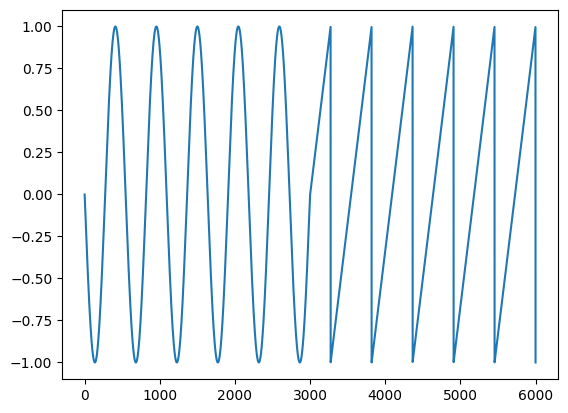

In [5]:
#Создание искусственного временного ряда
t = np.linspace(np.pi, 6 * 2 * np.pi, 3000)
ts = np.concatenate([np.sin(t), signal.sawtooth(t)])
plt.plot(ts)

In [6]:
#Поиск сниппетов
snp = snippets(ts, 600, 2, percentage=0.5)

600


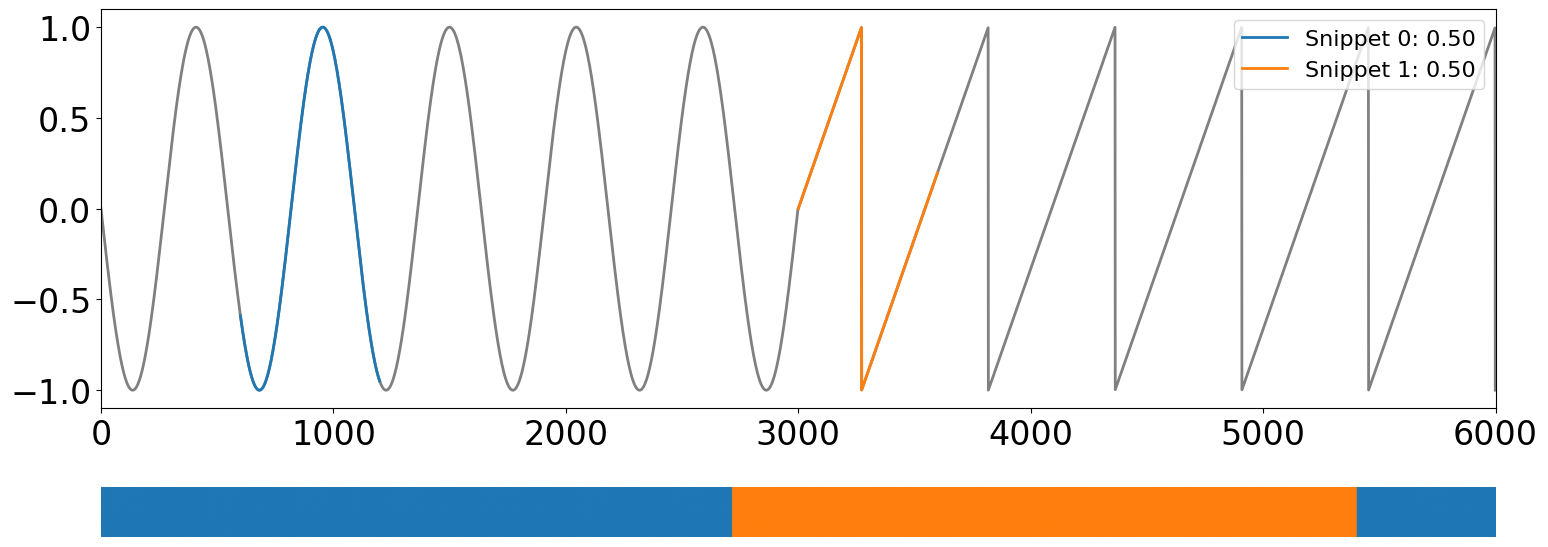

<Axes: >

In [7]:
#Визуализация результатов
plot_snippets(ts, snp)

Далее вам предстоит самостоятельно выполнить поиск top-$k$ типичных подпоследовательностей временного ряда (сниппетов) с помощью алгоритма SnippetFinder на наборе данных PAMAP. Описание набора данных находится в [README-файле](datasets/PAMAP/readme.md).

Выполните считывание временного ряда **показаний гироскопа на оси «Y» (угол тангажа) на временном интервале от 1790 сек. до 1930 сек.** (используя колонку с временными метками) из файла *PAMAP.txt*, который располагается в директории *./datasets/PAMAP*. Затем выполните поиск сниппетов с помощью функции `snippets()` из библиотеки stumpy. Затем визуализируйте полученные результаты, используя функцию `plot_snippets()` из модуля snippets.py.

In [9]:
pamap = np.loadtxt('./datasets/PAMAP/PAMAP.txt').T

time = pamap[:, 0]
mask = (time >= 1790) & (time <= 1930)

ts = pamap[mask, 11]
activity = pamap[mask, 1].astype(int)

m = 600
k = 2

snp = snippets(ts, m, k, percentage=0.5)

print("Количество отсчетов:", len(ts))
print("Виды активности:", np.unique(activity))
print("Индексы сниппетов:", snp[1])
# INSERT YOUR CODE

Количество отсчетов: 13430
Виды активности: [12 13]
Индексы сниппетов: [ 6000 10800]


Выполните визулизацию временного ряда и найденных сниппетов с помощью функции `plot_snippets()` из модуля snippets.py.

600


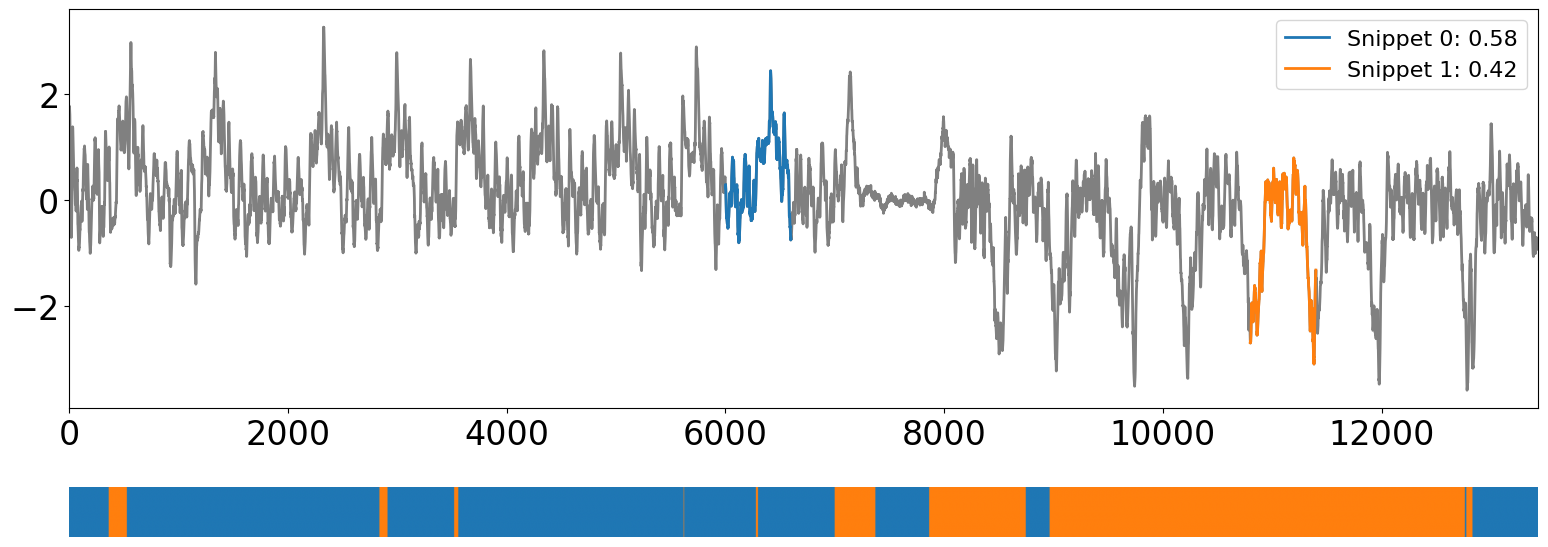

<Axes: >

In [ ]:
plot_snippets(ts, snp)

Оцените точность разметки, полученной при помощи сниппетов, используя исходные данные об активностях в ряде.

In [10]:
# INSERT YOUR CODE
regimes = snp[5]
n = snp[2].shape[1]

predicted = np.zeros(n, dtype=int)

for snippet_id, start, end in regimes:
    predicted[start:end] = snippet_id

true_labels = activity[m // 2:m // 2 + n]
true_binary = (true_labels == 13).astype(int)

acc1 = np.mean(predicted == true_binary)
acc2 = np.mean((1 - predicted) == true_binary)

accuracy = max(acc1, acc2)

print(f"Accuracy: {accuracy:.4f}")
print(f"Точность разметки: {accuracy * 100:.2f}%")

Accuracy: 0.9016
Точность разметки: 90.16%


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

В результате анализа показаний гироскопа по оси Y на интервале от 1790 до 1930 секунд найдены два типичных фрагмента временного ряда с начальными индексами 6000 и 10800. Первый сниппет представляет 58% анализируемых подпоследовательностей, второй - 42%. На графике видно, что найденные фрагменты соответствуют различным характерам колебаний гироскопа при подъеме и спуске по лестнице. При сравнении полученной разметки с исходными метками активности точность составила 90,16%. Это показывает, что использование сниппетов позволяет достаточно хорошо различать два вида движения, хотя отдельные участки определяются неправильно.

### Задача 2. Разметка многомерного временного ряда

Выполните разметку многомерного временно ряда, используя **показания гироскопа по всем трем осям** из набора данных PAMAP. Используйте тот же временной интервал, что и в задаче 1. Итоговую разметку получите в результате голосования большинством.

Длина разметки: 12831
Распределение классов: (array([0, 1]), array([7646, 5185]))


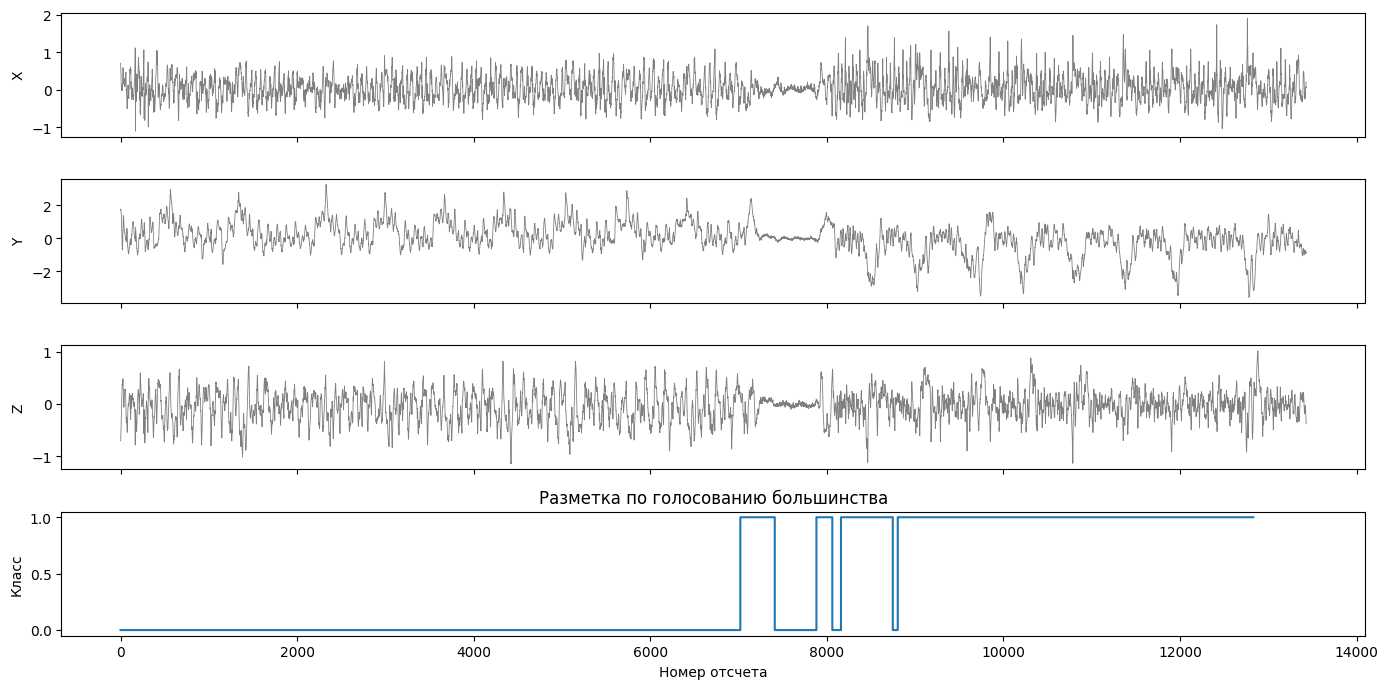

In [11]:
# INSERT YOUR CODE
gyro = pamap[mask, 10:13]

m = 600
k = 2

axis_results = []

for axis in range(3):
    result = snippets(gyro[:, axis], m, k, percentage=0.5)
    axis_results.append(result)

axis_labels = np.array([
    np.argmin(result[2], axis=0)
    for result in axis_results
])

for axis in (0, 2):
    if np.mean(axis_labels[axis] != axis_labels[1]) > 0.5:
        axis_labels[axis] = 1 - axis_labels[axis]

predicted_multi = (
    np.sum(axis_labels, axis=0) >= 2
).astype(int)

print("Длина разметки:", len(predicted_multi))
print("Распределение классов:", np.unique(predicted_multi, return_counts=True))

fig, ax = plt.subplots(4, 1, figsize=(14, 7), sharex=True)

for i, name in enumerate(["X", "Y", "Z"]):
    ax[i].plot(gyro[:, i], color="gray", linewidth=0.6)
    ax[i].set_ylabel(name)

ax[3].step(np.arange(len(predicted_multi)), predicted_multi, where="post")
ax[3].set_ylabel("Класс")
ax[3].set_xlabel("Номер отсчета")
ax[3].set_title("Разметка по голосованию большинства")

plt.tight_layout()
plt.show()

Оцените точность разметки многомерного ряда, используя исходные данные об активностях.

In [12]:
# INSERT YOUR CODE
true_labels = activity[m // 2:m // 2 + len(predicted_multi)]
true_binary = (true_labels == 13).astype(int)

acc1 = np.mean(predicted_multi == true_binary)
acc2 = np.mean((1 - predicted_multi) == true_binary)

accuracy_multi = max(acc1, acc2)

print(f"Accuracy: {accuracy_multi:.4f}")
print(f"Точность многомерной разметки: {accuracy_multi * 100:.2f}%")
print(f"Точность одномерной разметки: {90.16:.2f}%")

Accuracy: 0.9344
Точность многомерной разметки: 93.44%
Точность одномерной разметки: 90.16%


In [13]:
print("\nТочность по осям:")

for i, name in enumerate(["X", "Y", "Z"]):
    labels_axis = axis_labels[i]

    if acc2 > acc1:
        labels_axis = 1 - labels_axis

    acc_axis = np.mean(labels_axis == true_binary)

    print(f"Ось {name}: {acc_axis * 100:.2f}%")

print(f"\nГолосование большинства: {accuracy_multi * 100:.2f}%")


Точность по осям:
Ось X: 91.05%
Ось Y: 90.16%
Ось Z: 88.84%

Голосование большинства: 93.44%


❓ Проанализируйте и изложите содержательный смысл полученных результатов. Сравните полученные разметки многомерного и одномерного рядов.

Выполнена разметка временного ряда по трем осям гироскопа X, Y и Z на том же временном интервале, что и в первой задаче. Для каждой оси найдены два сниппета, после чего итоговая разметка получена голосованием большинства. Точность по оси X составила 91,05%, по оси Y - 90,16%, по оси Z - 88,84%. После объединения результатов трех осей точность увеличилась до 93,44%, что на 3,28 % выше результата одномерного ряда из задачи 1. Таким образом, использование показаний гироскопа по трем осям позволило уменьшить количество ошибок разметки и точнее выделить участки, соответствующие подъему и спуску по лестнице.

## Задача 3. Подбор оптимального значения _k_


Разработайте программу, которая выполняет выполняет вычисление меры $change$ для различных значений $k$ с помощью алгоритма SnippetFinder. Проведите эксперименты, используя временной ряд из задания 2 (взяв 1 ≤ _k_ ≤ 9).

$Change_k = \frac{ProfileArea_{k-1}}{ProfileArea_k} - 1$

In [14]:
# INSERT YOUR CODE
m = 600
k_values = np.arange(1, 10)

areas = []

for axis in range(3):
    result = snippets(gyro[:, axis], m, 9, percentage=0.5)
    areas.append(result[4])

profile_areas = np.mean(areas, axis=0)

changes = np.full(len(k_values), np.nan)

for i in range(1, len(k_values)):
    changes[i] = profile_areas[i - 1] / profile_areas[i] - 1

print(f"{'k':>3} | {'ProfileArea':>14} | {'change':>10}")
print("-" * 34)

for k, area, change in zip(k_values, profile_areas, changes):
    change_str = "—" if np.isnan(change) else f"{change:.4f}"
    print(f"{k:>3} | {area:>14.4f} | {change_str:>10}")

  k |    ProfileArea |     change
----------------------------------
  1 |    161070.9237 |          —
  2 |    139223.4116 |     0.1569
  3 |    126306.4469 |     0.1023
  4 |    117643.6987 |     0.0736
  5 |    109427.2331 |     0.0751
  6 |    101712.8492 |     0.0758
  7 |     94174.0402 |     0.0801
  8 |     87268.4330 |     0.0791
  9 |     80544.2977 |     0.0835


Выполните визуализацию результатов экспериментов в следующем виде: отображение столбчатых диаграм со значениями $ProfileArea$ и меры $change$ в зависимости от $k$.

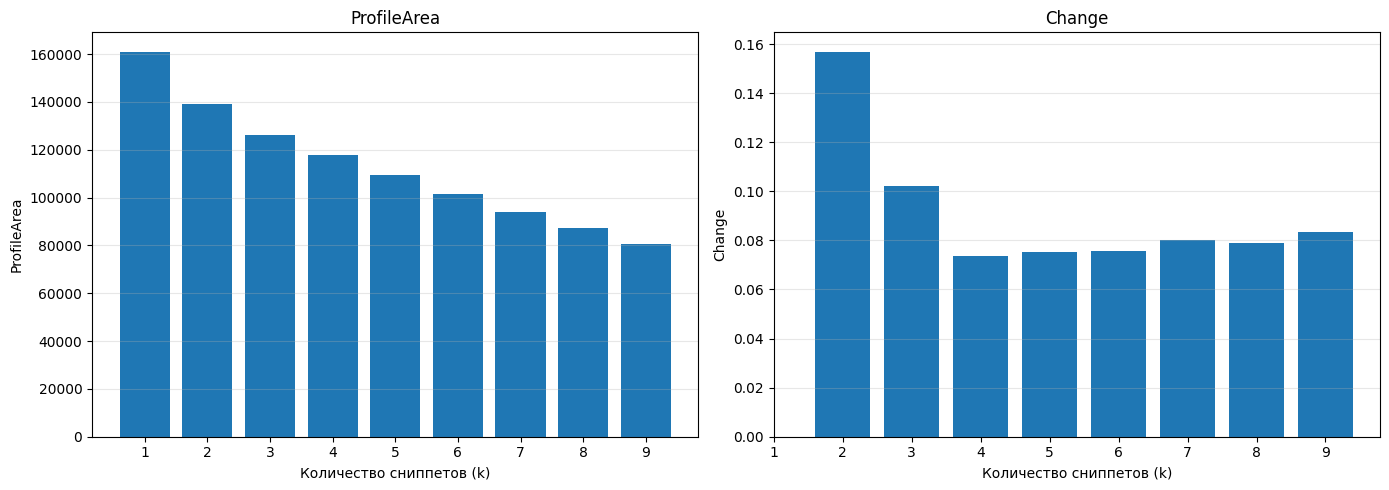

In [15]:
# INSERT YOUR CODE
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(k_values, profile_areas)
ax[0].set_title("ProfileArea")
ax[0].set_xlabel("Количество сниппетов (k)")
ax[0].set_ylabel("ProfileArea")
ax[0].set_xticks(k_values)
ax[0].grid(axis="y", alpha=0.3)

ax[1].bar(k_values[1:], changes[1:])
ax[1].set_title("Change")
ax[1].set_xlabel("Количество сниппетов (k)")
ax[1].set_ylabel("Change")
ax[1].set_xticks(k_values)
ax[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов. Какое значение $k$ является наилучшим для используемого временного ряда?

При увеличении количества сниппетов от 1 до 9 значение ProfileArea постепенно уменьшается с 161070,92 до 80544,30. Это означает, что большее количество сниппетов позволяет точнее представить характерные участки временного ряда. Однако наиболее заметное улучшение наблюдается при переходе от одного сниппета к двум, значение меры change достигает максимума 0,1569. При дальнейшем увеличении k значения change становятся меньше и находятся примерно в пределах от 0,07 до 0,10. Хотя ProfileArea продолжает уменьшаться, добавление новых сниппетов дает менее существенное улучшение.

Таким образом, оптимальным значением является k = 2, поскольку при таком количестве сниппетов достигается наибольшее относительное улучшение по мере change. Этот результат также согласуется с наличием двух видов активности в исследуемом временном ряду, подъема и спуска по лестнице.